# Task 5 — Model Training

**Saiket Systems | Machine Learning Internship**

Objective: train a binary classification model using the selected features and `Churn` as the target. This notebook uses the task-brief features **Contract**, **MonthlyCharges**, and **tenure**, and trains a Random Forest classifier.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

HERE = Path.cwd().resolve()
ROOT = next((p for p in [HERE, *HERE.parents] if (p / "Dataset").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find Dataset folder. Open this notebook inside Saiket_ML_Internship.")
DATA_PATH = ROOT / "Dataset" / "Telco_Customer_Churn_Dataset.csv"
df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True), errors="coerce"
)
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop_duplicates().copy()
y = df["Churn"].map({"No": 0, "Yes": 1})


## 1. Select input features and encode categories

`customerID` is an identifier and is excluded. The categorical `Contract` feature is one-hot encoded.

In [2]:
selected_features = ["Contract", "MonthlyCharges", "tenure"]
X = pd.get_dummies(df[selected_features], columns=["Contract"], drop_first=True, dtype=int)
print("Selected source features:", selected_features)
print("Encoded model inputs:", X.columns.tolist())
print("Input matrix shape:", X.shape)
display(X.head())


Selected source features: ['Contract', 'MonthlyCharges', 'tenure']
Encoded model inputs: ['MonthlyCharges', 'tenure', 'Contract_One year', 'Contract_Two year']
Input matrix shape: (7043, 4)


,MonthlyCharges,tenure,Contract_One year,Contract_Two year
0,29.85,1,0,0
1,56.95,34,1,0
2,53.85,2,0,0
3,42.30,45,1,0
4,70.70,2,0,0


## 2. Create an 80/20 stratified split

The same split settings are used across the training and evaluation notebooks so the results are reproducible.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")


Training samples: 5,634
Testing samples: 1,409


## 3. Train the Random Forest model

In [4]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    min_samples_leaf=2,
    n_jobs=-1
)
model.fit(X_train, y_train)
print("Random Forest training complete.")
print("Number of trees:", model.n_estimators)
print("Number of input features:", model.n_features_in_)


Random Forest training complete.
Number of trees: 300
Number of input features: 4


## 4. Inspect training feature importance

,importance
MonthlyCharges,0.498457
tenure,0.300243
Contract_Two year,0.133649
Contract_One year,0.067652


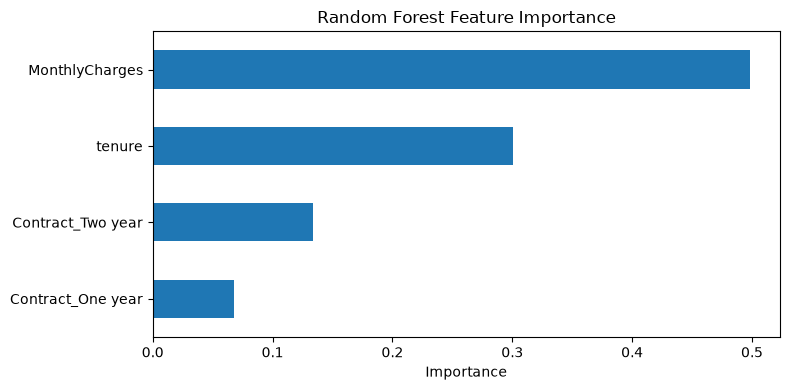

In [5]:
importance = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(importance.to_frame("importance"))
ax = importance.sort_values().plot(kind="barh", figsize=(8, 4))
ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


## 5. Training summary

In [6]:
print("Target mapping: No = 0, Yes = 1")
print("Features used:", ", ".join(selected_features))
print("Train/test split: 80% / 20%")
print("Model: RandomForestClassifier")
print("The testing data is held out for evaluation in Task 6.")


Target mapping: No = 0, Yes = 1
Features used: Contract, MonthlyCharges, tenure
Train/test split: 80% / 20%
Model: RandomForestClassifier
The testing data is held out for evaluation in Task 6.
